<h1 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 700; margin-bottom: 20px;">
Financial Distress Early Warning and Explainable ML System
</h1>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
<b>Author:</b> Eegunjobi Feranmi<br>
<b>Dataset:</b> Financial ratios and recorded bankruptcy outcomes for Polish companies<br>
<b>Tools:</b> Python, Pandas, Scikit learn, Logistic Regression, Gradient Boosted Trees, SHAP
</p>

<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600;">
Business Problem
</h2>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
Corporate insolvencies are rising worldwide, and global insolvencies rose 10 percent in 2024, putting them 12 percent above the 2016 to 2019 average. For banks, credit insurers and advisory firms, a single corporate failure can mean unrecoverable loans, unpaid claims or investment losses, yet analysts cannot manually review the financial statements of every borrower or investment target. They need an automated early warning system that screens companies at scale and shows why each one is flagged.
</p>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
This project builds a machine learning model that predicts bankruptcy risk from historical financial ratios, comparing a Logistic Regression baseline with a gradient boosted model and using SHAP to explain which ratios drive each company risk score. Because bankruptcies are rare, the models are judged on recall, precision and PR AUC rather than accuracy, and the decision threshold is tuned to balance missed bankruptcies against false alarms. The predicted probabilities are then converted into a risk ranked list so analysts can investigate the highest risk companies first. The prototype tests the approach on a public historical benchmark, and it does not prove why companies fail or that the model will work for present day Nigerian firms.
</p>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
<b>Business Question:</b> Can we predict whether a company is at risk of bankruptcy from its historical financial ratios and explain the reasons, so that analysts can prioritise which companies to investigate first?
</p>

<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600;">
Dataset
</h2>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
This project uses the Polish Companies Bankruptcy dataset from the UCI Machine Learning Repository, which provides five separate forecasting datasets. Only the first year file is used here, so all results apply to that file and not to the full collection. It contains 7,027 company observations, of which 271 (3.9 percent) went bankrupt during the specified forecast period and 6,756 (96.1 percent) did not, a ratio of roughly 25 healthy companies for every bankrupt one. The data consists of financial ratios drawn from historical company records, principally covering 2000 to 2013.
</p>

<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600;">
Step 1 — Import Libraries
</h2>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.io import arff
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600; text-align: left;">
Step 2 — Load the Data
</h2>

In [2]:
file_path = 'data/raw/1year.arff'

data, meta = arff.loadarff(file_path)
df = pd.DataFrame(data)

# Decode byte strings to normal strings (ARFF loads as bytes)
for col in df.select_dtypes([object]).columns:
    df[col] = df[col].apply(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)

# Quick check
df.head()

,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,...,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,class
0,0.200550,0.37951,0.39641,2.0472,32.3510,0.38825,0.249760,1.33050,1.1389,0.50494,...,0.121960,0.39718,0.87804,0.001924,8.4160,5.1372,82.658,4.4158,7.4277,0
1,0.209120,0.49988,0.47225,1.9447,14.7860,0.00000,0.258340,0.99601,1.6996,0.49788,...,0.121300,0.42002,0.85300,0.000000,4.1486,3.2732,107.350,3.4000,60.9870,0
2,0.248660,0.69592,0.26713,1.5548,-1.1523,0.00000,0.309060,0.43695,1.3090,0.30408,...,0.241140,0.81774,0.76599,0.694840,4.9909,3.9510,134.270,2.7185,5.2078,0
3,0.081483,0.30734,0.45879,2.4928,51.9520,0.14988,0.092704,1.86610,1.0571,0.57353,...,0.054015,0.14207,0.94598,0.000000,4.5746,3.6147,86.435,4.2228,5.5497,0
4,0.187320,0.61323,0.22960,1.4063,-7.3128,0.18732,0.187320,0.63070,1.1559,0.38677,...,0.134850,0.48431,0.86515,0.124440,6.3985,4.3158,127.210,2.8692,7.8980,0


<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600; text-align: left;">
Step 3 — Data Understanding
</h2>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px;">
Before any analysis, I want to understand the structure of the data. This includes checking data types, missing values, duplicates, and basic statistics. This is the first thing a data scientist does when working with a new dataset.
</p>

In [3]:
df.shape

(7027, 65)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7027 entries, 0 to 7026
Data columns (total 65 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Attr1   7024 non-null   float64
 1   Attr2   7024 non-null   float64
 2   Attr3   7024 non-null   float64
 3   Attr4   6997 non-null   float64
 4   Attr5   7019 non-null   float64
 5   Attr6   7024 non-null   float64
 6   Attr7   7024 non-null   float64
 7   Attr8   7002 non-null   float64
 8   Attr9   7026 non-null   float64
 9   Attr10  7024 non-null   float64
 10  Attr11  6988 non-null   float64
 11  Attr12  6997 non-null   float64
 12  Attr13  7027 non-null   float64
 13  Attr14  7024 non-null   float64
 14  Attr15  7025 non-null   float64
 15  Attr16  7002 non-null   float64
 16  Attr17  7002 non-null   float64
 17  Attr18  7024 non-null   float64
 18  Attr19  7027 non-null   float64
 19  Attr20  7027 non-null   float64
 20  Attr21  5405 non-null   float64
 21  Attr22  7024 non-null   float64
 22  

In [5]:
pd.set_option('display.max_columns', None)

df.describe()

,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,Attr11,Attr12,Attr13,Attr14,Attr15,Attr16,Attr17,Attr18,Attr19,Attr20,Attr21,Attr22,Attr23,Attr24,Attr25,Attr26,Attr27,Attr28,Attr29,Attr30,Attr31,Attr32,Attr33,Attr34,Attr35,Attr36,Attr37,Attr38,Attr39,Attr40,Attr41,Attr42,Attr43,Attr44,Attr45,Attr46,Attr47,Attr48,Attr49,Attr50,Attr51,Attr52,Attr53,Attr54,Attr55,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64
count,7024.000000,7024.000000,7024.000000,6997.000000,7.019000e+03,7024.000000,7024.000000,7002.000000,7026.000000,7024.000000,6988.000000,6997.000000,7027.000000,7024.000000,7.025000e+03,7002.000000,7002.000000,7024.000000,7027.000000,7.027000e+03,5405.000000,7024.000000,7027.000000,6903.000000,7024.000000,7002.000000,6.716000e+03,6993.000000,7024.000000,7027.000000,7027.000000,6989.000000,6997.000000,7002.000000,7024.000000,7024.000000,4287.000000,7024.000000,7027.000000,6997.000000,6943.000000,7027.000000,7.027000e+03,7.027000e+03,6893.000000,6996.000000,6998.000000,7024.000000,7027.000000,7002.000000,7024.000000,6998.000000,6993.000000,6993.000000,7.027000e+03,7.027000e+03,7026.000000,7.027000e+03,7026.000000,6.892000e+03,7005.000000,7.027000e+03,6997.000000,6993.000000
mean,0.034660,0.560215,0.119969,2.629143,-2.631672e+02,0.059712,0.313876,2.623996,5.552855,1.825832,0.354393,0.799824,2.093345,0.313876,1.802696e+03,0.870690,3.751868,0.313876,0.462392,1.162128e+03,10.367516,0.288163,0.423610,0.540231,1.264430,0.831449,1.321989e+03,2.702905,4.194831,23.568949,0.473717,236.571445,7.144093,3.666283,0.306880,5.900730,173.453694,1.911897,0.269342,0.826132,0.604475,0.263638,4.588504e+03,3.426404e+03,-30.208158,1.853339,86.752262,0.148865,-1.367363,2.039821,0.467683,0.584584,98.720579,99.636002,8.855693e+03,-1.577367e+02,0.193243,1.587409e+02,0.277829,4.328830e+02,15.642228,4.763202e+03,8.126852,208.731950
std,4.565504,5.350084,5.275459,13.257356,3.707460e+04,6.051113,8.353274,18.708327,101.995448,33.836452,8.658758,5.316444,159.699448,8.353274,8.392232e+04,5.595342,19.514235,8.353274,30.646874,9.315822e+04,417.358298,8.337193,29.742101,13.501067,28.976962,7.781771,3.550416e+04,27.434030,0.677757,1826.847970,30.647711,4841.844793,17.077782,16.338097,7.565155,101.995601,6339.491580,33.835785,27.064231,12.594535,13.834767,27.071123,3.627309e+05,2.696211e+05,3088.908964,12.882415,1131.891001,7.793534,107.717867,5.039658,5.278947,8.527220,2785.367407,2799.586619,7.247527e+04,1.322125e+04,4.344046,1.322124e+04,6.339149,2.612802e+04,261.554534,3.107835e+05,19.996419,5140.708804
min,-256.890000,-72.162000,-440.500000,0.000000,-2.722100e+06,-397.890000,-189.560000,-141.410000,0.000005,-440.550000,-189.450000,-23.207000,-607.420000,-189.560000,-5.611900e+06,-42.322000,-0.412920,-189.560000,-622.060000,0.000000e+00,-1325.000000,-216.800000,-634.590000,-189.560000,-459.560000,-21.793000,-1.479000e+04,-490.090000,0.176090,-149.070000,-622.060000,0.000000,0.000000,-280.260000,-169.470000,0.000005,-525.520000,-440.550000,-701.630000,-101.270000,-77.791000,-701.630000,0.000000e+00,0.000000e+00,-256230.000000,-101.260000,0.000000,-218.420000,-9001.000000,0.000000,0.000000,0.000000,-130.470000,-122.030000,-8.004700e+05,-1.108300e+06,-315.370000,-4.194000e-03,-327.970000,4.700000e-05,0.000016,0.000000e+00,0.000015,0.000010
25%,0.021182,0.296678,0.026968,1.063100,-4.449800e+01,0.000000,0.028023,0.445710,1.037225,0.300785,0.038218,0.063057,0.038073,0.028023,3.435400e+02,0.122810,1.467025,0.028023,0.014812,1.708300e+01,1.024400,0.020362,0.011253,0.049077,0.195252,0.110262,2.353975e-01,0.050522,3.720875,0.094681,0.019233,48.291000,3.050500,0.247445,0.023120,1.264700,1.296500,0.419380,0.012786,0.052276,0.034762,0.011540,6.525600e+01,3.387300e+01,0.102010,0.610012,18.293000,-0.016980,-0.009992,0.805425,0.216135,0.132110,0.715110,0.972140,9.712000e+01,2.031450e-02,0.056772,8.647650e-01,0.000000,5.923950e+00,4.829000,4.322250e+01,3.425400,2.538600
50%,0.075802,0.482960,0.181275,1.502000,-5.373900e+00,0.000000,0.090109,1.015

In [6]:
(df.isnull().mean() * 100).loc[lambda x: x > 0].sort_values(ascending=False).round(2).to_frame(name='Percentage of Missing Values')

,Percentage of Missing Values
Attr37,38.99
Attr21,23.08
Attr27,4.43
Attr60,1.92
Attr45,1.91
Attr24,1.76
Attr41,1.20
Attr11,0.56
Attr32,0.54
Attr28,0.48


In [7]:
df.duplicated().sum()

np.int64(82)

In [8]:
c = df.iloc[:, -1].astype(str).str.extract(r'(\d)').astype(int).iloc[:,0]

pd.DataFrame({
    'Status': ['Bankrupt', 'Not Bankrupt'],
    'Number of Companies': [(c == 1).sum(), (c == 0).sum()]
})

,Status,Number of Companies
0,Bankrupt,271
1,Not Bankrupt,6756


---
### Step 4 — Exploratory Data Analysis
The goal is to find patterns in the dataset.

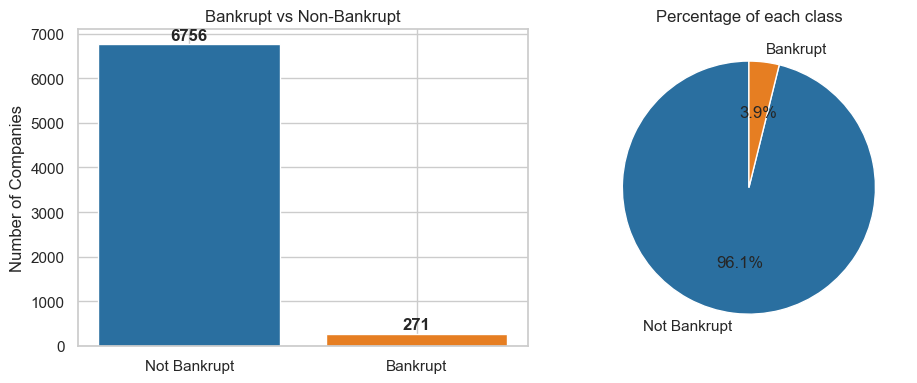

In [9]:
# How rare is bankruptcy in the dataset?

y = df.iloc[:, -1].astype(str).str.extract(r'(\d)').astype(int).iloc[:,0]
counts = y.value_counts().sort_index() # 0 = Not Bankrupt, 1 = Bankrupt
labels = ['Not Bankrupt', 'Bankrupt']

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# 1. Bar chart
ax[0].bar(labels, counts.values, color=['#2a6fa0', '#e67e22'])
ax[0].set_title('Bankrupt vs Non-Bankrupt')
ax[0].set_ylabel('Number of Companies')
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# 2. Pie chart
ax[1].pie(counts.values, labels=labels, autopct='%1.1f%%', colors=['#2a6fa0', '#e67e22'], startangle=90)
ax[1].set_title('Percentage of each class')

plt.tight_layout()
plt.show()

Bankruptcy cases make up only 3.9% of all companies (271 out of 7,027). This extreme imbalance means the model needs special handling, so we will use class_weight to make the model pay more attention to bankrupt cases.

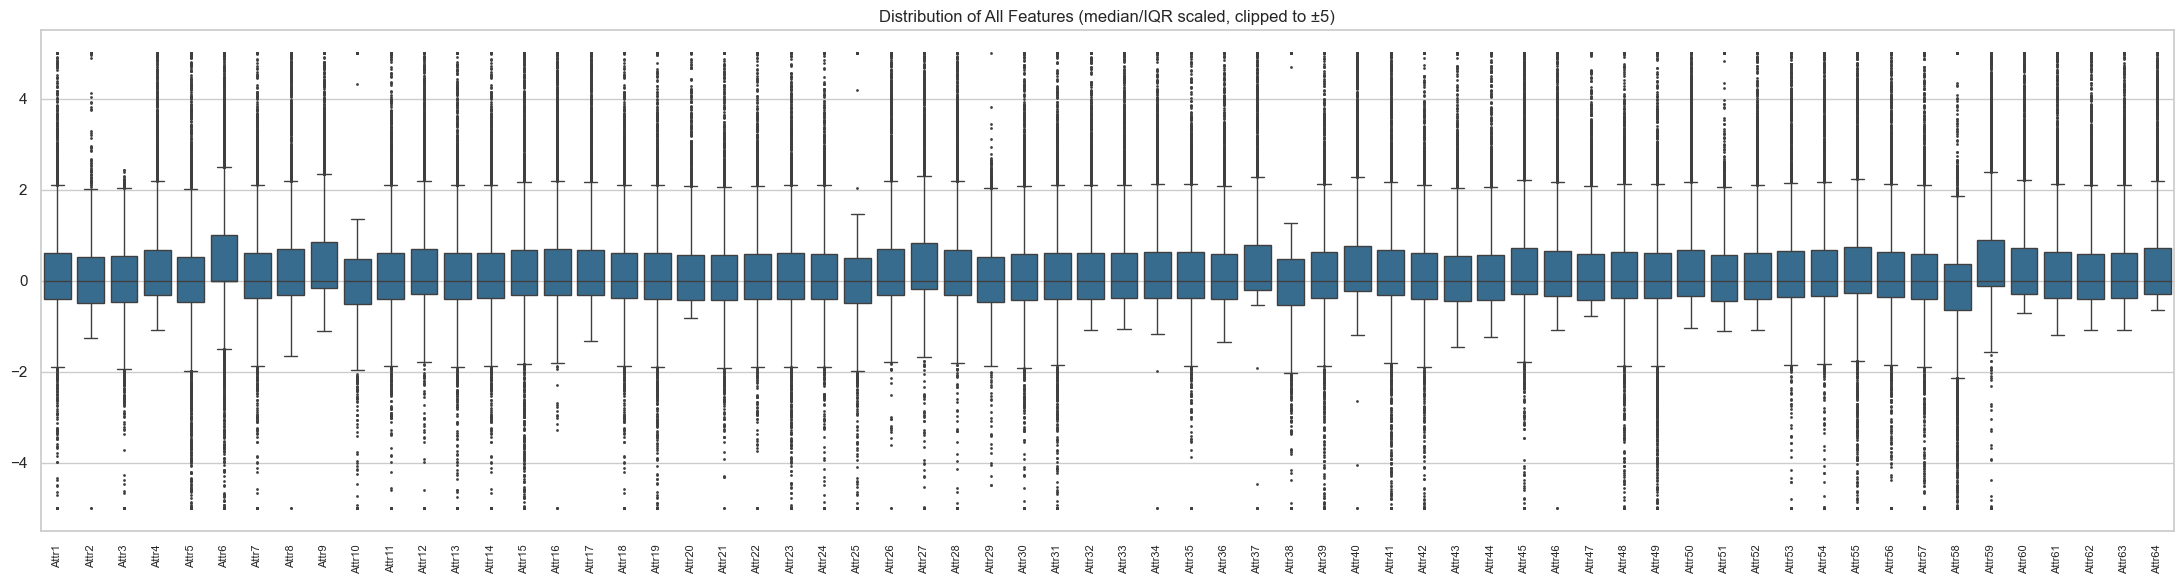

In [10]:
#How are the financial ratios distributed?

features = [f'Attr{i}' for i in range(1, 65)]
scaled = (df[features] - df[features].median()) / (df[features].quantile(0.75) - df[features].quantile(0.25))
scaled = scaled.clip(-5, 5)

plt.figure(figsize=(22, 6))
sns.boxplot(data=scaled, color='#2a6f9d', fliersize=1)
plt.xticks(rotation=90, fontsize=8)
plt.title('Distribution of All Features (median/IQR scaled, clipped to ±5)')
plt.tight_layout()
plt.show()

After median/IQR scaling, the core of most features (the central 50% of values) sits tightly around zero, but nearly all of them show long tails of extreme outliers reaching the ±5 clipping limit on both sides. This indicates that the financial ratios are heavily skewed and outlier-prone, and the true extremes are larger than displayed since values were clipped. Only a few features have noticeably shorter tails.

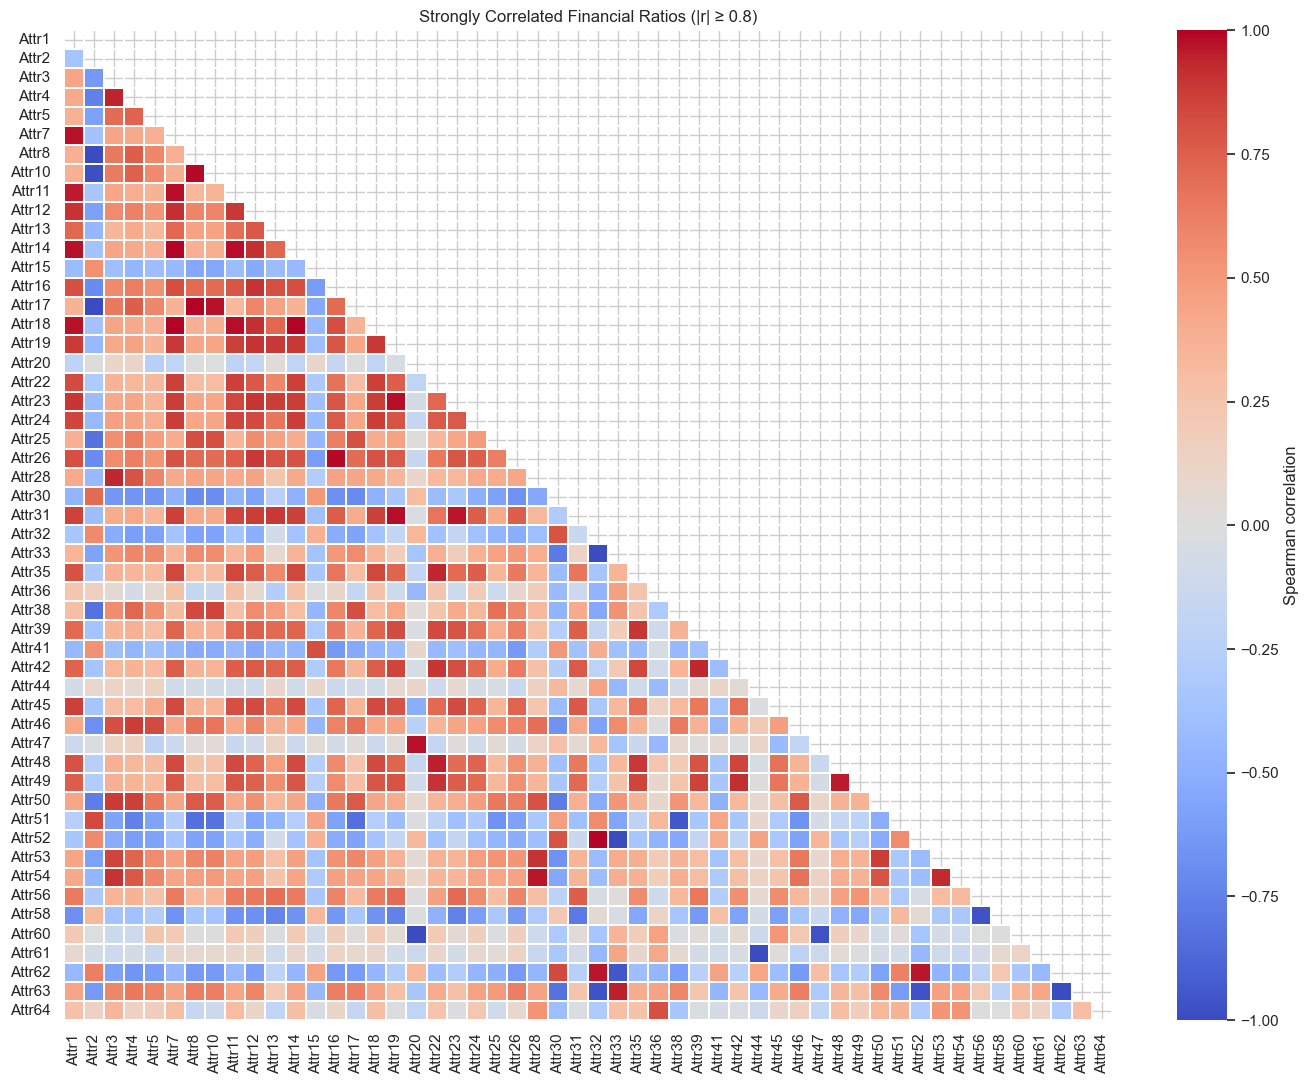

In [11]:
#Which financial ratios are strongly correlated with one another?

corr = df[features].corr(method='spearman')
strong = (corr.abs() >= 0.8) & (corr.abs() < 1)
involved = corr.columns[strong.any()]
sub = corr.loc[involved, involved]

plt.figure(figsize=(14, 11))
sns.heatmap(sub, mask=np.triu(np.ones_like(sub, dtype=bool)), cmap='coolwarm',
            center=0, vmin=-1, vmax=1, linewidths=0.3, cbar_kws={'label': 'Spearman correlation'})
plt.title('Strongly Correlated Financial Ratios (|r| ≥ 0.8)')
plt.tight_layout()
plt.show()

Many ratios are highly correlated, so the baseline will use Elastic Net Logistic Regression, whose L2 penalty lets correlated ratios share weight and whose L1 penalty removes redundant ones. Gradient boosting is not strongly affected by correlated features, so its predictive performance is expected to hold. Because SHAP spreads credit across related ratios, the explanations will be read as the contribution of groups of related ratios rather than any single one. Any correlation-based selection will be computed on the training set only to avoid leaking test information.

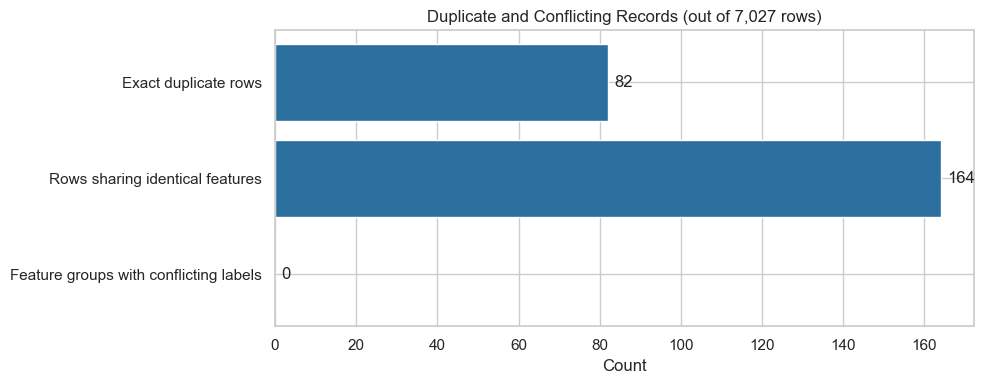

In [12]:
#Are there duplicate records or conflicting observations?

exact_dups = df.duplicated().sum()
same_features = df.duplicated(subset=features, keep=False).sum()
conflicting_groups = (df[df.duplicated(subset=features, keep=False)]
                      .groupby(features, dropna=False)['class'].nunique().gt(1).sum())

labels = ['Exact duplicate rows', 'Rows sharing identical features', 'Feature groups with conflicting labels']
values = [exact_dups, same_features, conflicting_groups]

plt.figure(figsize=(10, 4))
bars = plt.barh(labels, values, color=['#2a6f9d', '#2a6f9d', '#e67e22'])
for bar, v in zip(bars, values):
    plt.text(v + max(values + [1]) * 0.01, bar.get_y() + bar.get_height() / 2, f'{v:,}', va='center')
plt.title(f'Duplicate and Conflicting Records (out of {len(df):,} rows)')
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

The data contains 82 exact duplicate rows (about 1.2% of the 7,027 records), and 164 rows share identical feature values, which is consistent with the duplicates being repeated copies of 82 original records. No group of identical feature values carries conflicting bankruptcy labels, so the duplicates do not introduce label noise. This means the duplication is a data quality issue to be aware of rather than a source of contradictory information.

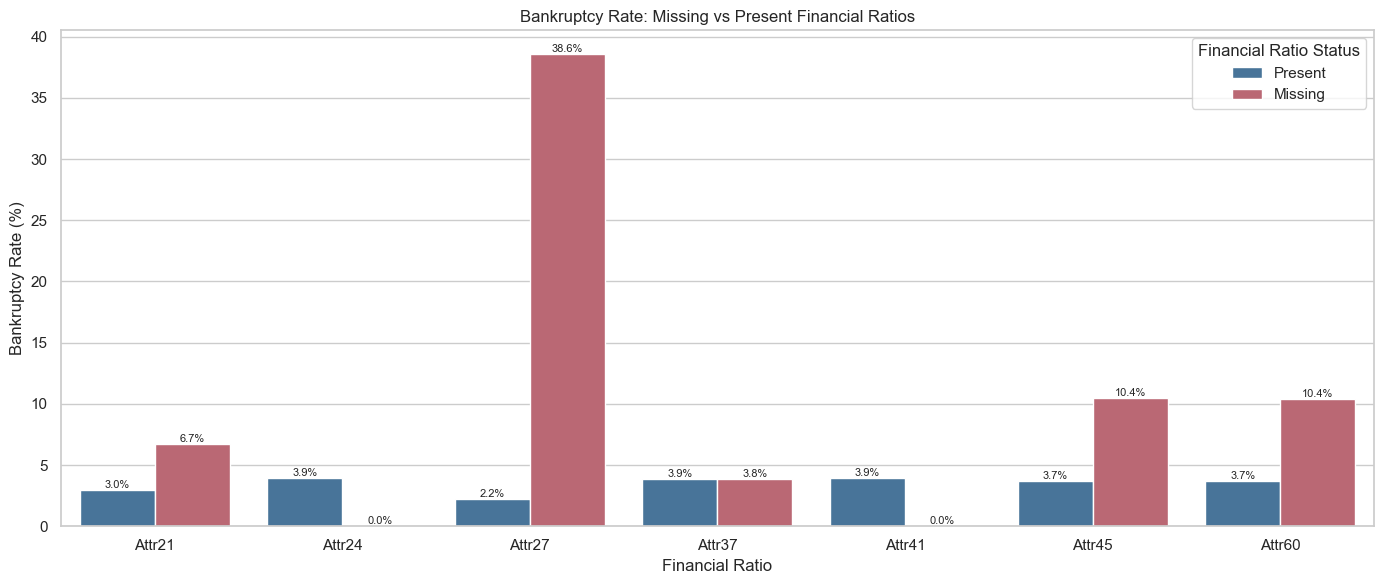

In [13]:
#Is missingness associated with bankruptcy?

bankrupt_label = df['class'].value_counts().idxmin()  
df['is_bankrupt'] = (df['class'] == bankrupt_label).astype(int)

min_missing = 80  
rows = []
for col in features:
    if df[col].isna().sum() >= min_missing:
        for status, mask in [('Present', df[col].notna()), ('Missing', df[col].isna())]:
            rows.append({'Attribute': col, 'Missing Status': status,
                         'Bankruptcy Rate (%)': df.loc[mask, 'is_bankrupt'].mean() * 100})

result = pd.DataFrame(rows)

plt.figure(figsize=(14, 6))
ax = sns.barplot(data=result, x='Attribute', y='Bankruptcy Rate (%)', hue='Missing Status',
                 hue_order=['Present', 'Missing'], palette={'Present': '#3b75a6', 'Missing': '#c85a6b'})
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', fontsize=8)
plt.title('Bankruptcy Rate: Missing vs Present Financial Ratios')
plt.xlabel('Financial Ratio')
plt.legend(title='Financial Ratio Status')
plt.tight_layout()
plt.show()

Missingness is informative for several ratios. Companies with a missing Attr27 have a bankruptcy rate of 38.6% against 2.2% when it is present, and Attr45 and Attr60 show a similar pattern (10.4% vs 3.7%). This indicates that missing values are not random for some ratios, so the absence of a value may itself signal financial distress.

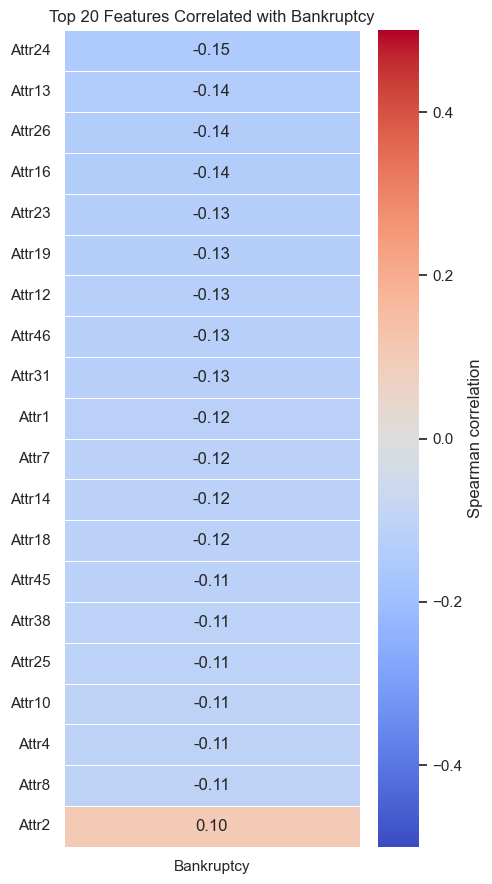

In [14]:
# Which columns are most correlated with bankruptcy?

bankrupt_label = df['class'].value_counts().idxmin()     
target = (df['class'] == bankrupt_label).astype(int)

corr_target = df[features].corrwith(target, method='spearman')
top = corr_target.reindex(corr_target.abs().sort_values(ascending=False).head(20).index)

plt.figure(figsize=(5, 9))
sns.heatmap(top.to_frame('Bankruptcy'), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-0.5, vmax=0.5, linewidths=0.5,
            cbar_kws={'label': 'Spearman correlation'})
plt.title('Top 20 Features Correlated with Bankruptcy')
plt.tight_layout()
plt.show()

Individual financial ratios show only weak correlations with bankruptcy. Among the 20 strongest, Spearman coefficients range from about -0.15 to +0.10, and nearly all are negative, meaning higher values of these ratios are slightly associated with lower bankruptcy risk. No single ratio is a strong predictor on its own, which suggests that predictive signal is more likely to come from combinations of ratios and non-linear relationships than from any one feature.

<div style="border-top: 1.5px solid #bfbfbf; padding-top: 45px; margin-top: 20px; font-family: 'Segoe UI', -apple-system, BlinkMacSystemFont, Helvetica, Arial, sans-serif; max-width: 850px;">

<h2 style="font-size: 28px; font-weight: 700; color: #1f1f1f; margin: 0 0 14px 0; letter-spacing: -0.2px;">
Step 5 — Data Cleaning
</h2>

<p style="font-size: 16.5px; line-height: 1.6; font-weight: 400; color: #2b2b2b; margin: 0;">
The 82 exact duplicate rows were removed, reducing the dataset from 7,027 to 6,945 companies. All of them were non-bankrupt, so the 271 bankrupt cases are unchanged. The target was converted to a clean 0/1 label and all 64 financial ratios were confirmed to be numeric. After cleaning, 6,674 companies are non-bankrupt and 271 are bankrupt (3.9%), so the class imbalance is essentially unchanged.

</p>

</div>

In [15]:
# 0. Remove helper columns created earlier for plotting
df = df.drop(columns=['is_bankrupt'], errors='ignore')

# 1. Clean the target
df['class'] = (df['class'].astype(str)
                          .str.replace(r"[b'\" ]", "", regex=True)
                          .astype(int))

# 2. Make every Attr column numeric
df[features] = df[features].apply(pd.to_numeric, errors='coerce')

# 3. Drop exact duplicate rows
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)

# 4. Checks
extra_cols = [c for c in df.columns if c not in features + ['class']]
print(f'Rows before: {rows_before:,} | after: {len(df):,} | removed: {rows_before - len(df)}')
print('Target values:', sorted(df['class'].unique()))
print(df['class'].value_counts())
print('Non-numeric feature columns:', [c for c in features if not pd.api.types.is_numeric_dtype(df[c])])
print('Unexpected extra columns:', extra_cols, '| total columns:', df.shape[1])   # expect [] and 65

Rows before: 7,027 | after: 6,945 | removed: 82
Target values: [np.int64(0), np.int64(1)]
class
0    6674
1     271
Name: count, dtype: int64
Non-numeric feature columns: []
Unexpected extra columns: [] | total columns: 65
